# Spike Encoding

Spiking networks need their inputs as spikes. `braintools` provides ten encoders that turn numbers or time series into spike trains (or, in one case, a current). They fall into four groups:

| Group | Encoders | Information is carried by |
|---|---|---|
| Rate codes (stochastic) | `RateEncoder`, `PoissonEncoder`, `BernoulliEncoder`, `PopulationEncoder` | how often a neuron fires |
| Timing codes (deterministic) | `LatencyEncoder`, `RankOrderEncoder`, `SpikeCountEncoder` | when, in what order, or how many times a neuron fires |
| Signal codes | `DeltaEncoder`, `StepCurrentEncoder` | changes of a time series, or a constant current |
| Symbol codes | `TemporalEncoder` | which neuron fires, with a fixed spike pattern per symbol |

Conventions shared by all encoders:

- the time step comes from `brainstate.environ` (set it with a unit, e.g. `0.1 * u.ms`);
- `n_time` is the **number of time steps**; outputs have shape `(n_time, *data.shape)` (the population encoder adds a neuron axis);
- stochastic encoders draw from `brainstate.random`, so seed it with `brainstate.random.seed(...)`;
- a firing rate is recovered from a spike matrix as `spikes.mean(axis=0) / dt`.

## 1. Setup

In [1]:
import brainstate
import brainunit as u
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import braintools

dt = 0.1 * u.ms
brainstate.environ.set(dt=dt)
brainstate.random.seed(0)
dt_s = dt.to_decimal(u.second)


def raster(ax, spikes, title):
    s = np.asarray(spikes)
    t_idx, n_idx = np.nonzero(s)
    ax.plot(t_idx * dt.to_decimal(u.ms), n_idx, "|", ms=8, color="k")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("time (ms)")
    ax.set_ylim(-0.5, s.shape[1] - 0.5)

## 2. Rate Codes

**`RateEncoder(gain, method, min_rate, max_rate)`** maps an input $x \in [0, 1]$ to a rate between `min_rate` and `max_rate` (default `gain`), linearly, through $(e^x - 1)/(e - 1)$, or through $\sqrt x$, then fires in each step with probability $\text{rate} \cdot dt$. **`PoissonEncoder`** takes rates in Hz directly (or $x \cdot$ `max_rate` with `normalize=True`) and returns 1 when a Poisson draw with mean $\text{rate}\cdot dt$ is positive, so the firing probability per step is $1 - e^{-\text{rate}\cdot dt}$. The two agree at low rates; the Poisson version saturates more smoothly at high ones.

In [2]:
n = 400_000  # 40 s, so the estimates are within about 1 Hz
x = jnp.array([0.2, 0.5, 0.8])
print("RateEncoder, gain 100 Hz:")
for method, f in [("linear", lambda v: v), ("exponential", lambda v: (np.exp(v) - 1) / (np.e - 1)), ("sqrt", np.sqrt)]:
    measured = braintools.RateEncoder(gain=100.0, method=method)(x, n).mean(axis=0) / dt_s
    print(f"  {method:11s} measured {np.round(np.asarray(measured), 1)} Hz, expected {np.round(100 * f(np.asarray(x)), 1)} Hz")

rates = jnp.array([20.0, 200.0, 2000.0])
p_spike = braintools.PoissonEncoder()(rates, n).mean(axis=0)
print("\nPoissonEncoder, P(spike per step):")
print("  measured ", np.round(np.asarray(p_spike), 4))
print("  1-exp(-r dt)", np.round(1 - np.exp(-np.asarray(rates) * dt_s), 4), " vs  r*dt", np.asarray(rates) * dt_s)

RateEncoder, gain 100 Hz:


  linear      measured [19.7 48.5 81. ] Hz, expected [20. 50. 80.] Hz
  exponential measured [12.8 37.  71.6] Hz, expected [12.9 37.8 71.3] Hz
  sqrt        measured [46.3 70.4 92. ] Hz, expected [44.7 70.7 89.4] Hz



PoissonEncoder, P(spike per step):
  measured  [0.0021 0.0198 0.1822]
  1-exp(-r dt) [0.002  0.0198 0.1813]  vs  r*dt [0.002      0.02       0.19999999]


**`BernoulliEncoder(scale)`** fires with probability $x \cdot \text{scale}$ **per time step**, independently of `dt`: the same input gives ten times the rate in Hz if `dt` is ten times smaller. Use it when the probability per step is what you want to control (for example, image pixels presented for a fixed number of steps).

In [3]:
for step in [0.1 * u.ms, 1.0 * u.ms]:
    with brainstate.environ.context(dt=step):
        s = braintools.BernoulliEncoder(scale=0.5)(jnp.array([0.4]), 50_000)
        print(f"dt = {step}: P(spike) {float(s.mean()):.3f} (0.4 * 0.5 = 0.2), rate {float(s.mean()) / step.to_decimal(u.second):.0f} Hz")

dt = 0.1 ms: P(spike) 0.199 (0.4 * 0.5 = 0.2), rate 1994 Hz
dt = 1. ms: P(spike) 0.201 (0.4 * 0.5 = 0.2), rate 201 Hz


**`PopulationEncoder(n_neurons, min_val, max_val, sigma, max_rate)`** represents a scalar with a population of neurons whose preferred values are evenly spaced; neuron $i$ fires at $\text{max\_rate}\cdot e^{-(x - c_i)^2 / 2\sigma^2}$. The output has shape `(n_time, n_neurons)` for a scalar input. The value can be read back from the spike counts, for example with a population-vector average of the preferred values:

input 0.25: decoded 0.245, spikes per neuron [ 13  56 161 185  86  30   1   0   0   0   0   0]
input 0.60: decoded 0.597, spikes per neuron [  0   0   0   1  15  74 174 181  87  20   1   0]


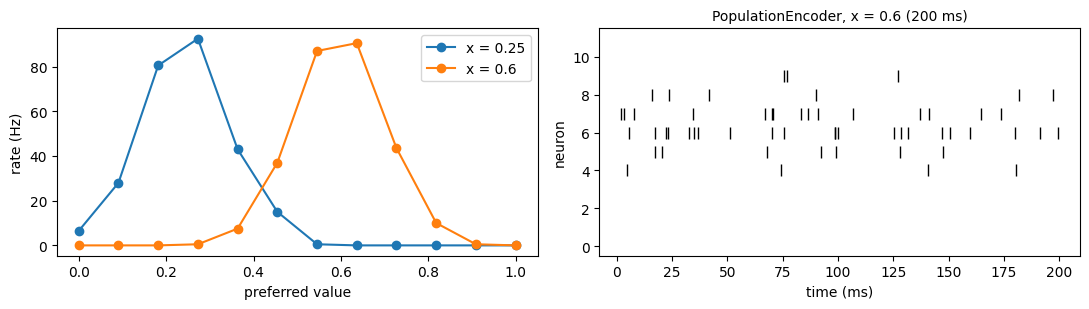

In [4]:
pop = braintools.PopulationEncoder(n_neurons=12, min_val=0.0, max_val=1.0, sigma=0.1, max_rate=100.0)
centers = np.asarray(pop.centers)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for value in [0.25, 0.6]:
    spikes = pop(value, 20_000)  # 2 s
    counts = np.asarray(spikes.sum(axis=0))
    decoded = (counts * centers).sum() / counts.sum()
    print(f"input {value:.2f}: decoded {decoded:.3f}, spikes per neuron {counts.astype(int)}")
    axes[0].plot(centers, counts / 2.0, "o-", label=f"x = {value}")
axes[0].set_xlabel("preferred value")
axes[0].set_ylabel("rate (Hz)")
axes[0].legend()
raster(axes[1], pop(0.6, 2000), "PopulationEncoder, x = 0.6 (200 ms)")
axes[1].set_ylabel("neuron")
fig.tight_layout()
plt.show()

## 3. Timing Codes

**`LatencyEncoder`** gives every feature exactly one spike, earlier for larger values. `n_time` is the window in steps (a quantity is converted with `dt`; the default window is `tau`).

- `method='linear'`: $t = t_0 + T(1 - x)$.
- `method='log'`: $t = t_0 + T \log\frac{x}{x - \theta}$, the time a leaky integrator driven by $x$ needs to reach threshold $\theta$.
- `normalize=True` chooses $T$ so the slowest input ($x = 0$ for linear, $x = \theta$ for log) fires in the last step. `normalize=False` uses the physical time constant `tau` instead and drops spikes that would fall after the window.
- `clip=True` silences inputs below `threshold`.

In [5]:
x = jnp.array([0.0, 0.25, 0.5, 0.75, 1.0])
lin = braintools.LatencyEncoder(method="linear", normalize=True)(x, n_time=101)
print("linear, normalized, 101 steps:      spike step", np.asarray(jnp.argmax(lin, axis=0)))

log = braintools.LatencyEncoder(method="log", normalize=True, threshold=0.05)(jnp.array([0.05, 0.1, 0.25, 0.5, 1.0]), n_time=101)
print("log, normalized, x = .05 .. 1:      spike step", np.asarray(jnp.argmax(log, axis=0)))

phys = braintools.LatencyEncoder(method="linear", normalize=False, tau=5 * u.ms)(x, n_time=3 * u.ms)
print(f"linear, tau = 5 ms, 3 ms window ({phys.shape[0]} steps): spikes per feature {np.asarray(phys.sum(0)).astype(int)} "
      f"(x = 0 and 0.25 would fire at 5 and 3.75 ms)")

linear, normalized, 101 steps:      spike step [100  75  50  25   0]
log, normalized, x = .05 .. 1:      spike step [100   5   2   1   0]
linear, tau = 5 ms, 3 ms window (30 steps): spikes per feature [0 0 1 1 1] (x = 0 and 0.25 would fire at 5 and 3.75 ms)


The log code is strongly compressed: inputs well above threshold all fire within the first few steps, and resolution is concentrated just above the threshold. Use `'linear'` when inputs are spread evenly over $[0, 1]$.

**`RankOrderEncoder`** also emits one spike per feature, larger values first. With `use_values=True` the time is proportional to $1 - x$ after rescaling the vector to $[0, 1]$ (equal values fire together); with `use_values=False` only the rank matters and spikes are evenly spaced. `invert=True` reverses the order.

In [6]:
v = jnp.array([0.1, 0.11, 0.9, 0.91, 0.5])
by_value = jnp.argmax(braintools.RankOrderEncoder(use_values=True)(v, n_time=50), axis=0)
by_rank = jnp.argmax(braintools.RankOrderEncoder(use_values=False)(v, n_time=50), axis=0)
print("values:          ", np.asarray(v))
print("use_values=True: ", np.asarray(by_value), "(close values fire together)")
print("use_values=False:", np.asarray(by_rank), "(evenly spaced by rank)")

values:           [0.1  0.11 0.9  0.91 0.5 ]
use_values=True:  [49 48  0  0 24] (close values fire together)
use_values=False: [39 29  9  0 19] (evenly spaced by rank)


**`SpikeCountEncoder(max_spikes, distribution)`** fires exactly $\lfloor x \cdot \text{max\_spikes}\rfloor$ times in the window, spread evenly (`'uniform'`) or at random distinct steps (`'random'`). With `normalize=True` (default) inputs are clipped to $[0, 1]$; a window can hold at most `n_time` spikes.

In [7]:
x = jnp.array([0.0, 0.35, 0.7, 1.0])
for dist in ["uniform", "random"]:
    s = braintools.SpikeCountEncoder(max_spikes=10, distribution=dist)(x, n_time=200)
    print(f"{dist:7s} counts {np.asarray(s.sum(axis=0)).astype(int)}  (floor(10 x) = {np.floor(10 * np.asarray(x)).astype(int)})")

uniform counts [ 0  3  7 10]  (floor(10 x) = [ 0  3  7 10])


random  counts [ 0  3  7 10]  (floor(10 x) = [ 0  3  7 10])


## 4. Signal Codes

**`DeltaEncoder(threshold)`** encodes a time series `(n_time, *features)` by send-on-delta modulation: it keeps a reference level, emits an event when the signal has moved `threshold` away from it, and resets the reference to the current value. Events are $+1$ for increases and $-1$ for decreases (ON/OFF), or 0/1 with `absolute=True` or `positive_only=True`. With `normalize=True` each feature is first rescaled to $[0, 1]$ over time, so `threshold` is a fraction of its range.

Because every event marks a change of about `threshold`, the signal can be approximately reconstructed by summing the events:

105 events (51 ON, 54 OFF); max |reconstruction error| 0.068 (threshold 0.05)


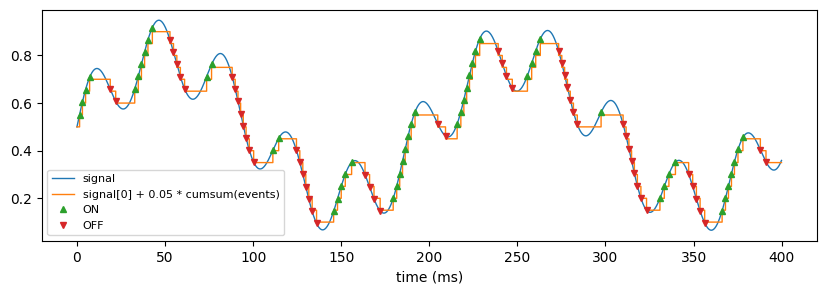

In [8]:
t = np.arange(4000) * dt.to_decimal(u.ms)  # 400 ms
signal = 0.5 + 0.3 * np.sin(2 * np.pi * t / 200) + 0.15 * np.sin(2 * np.pi * t / 37)
events = np.asarray(braintools.DeltaEncoder(threshold=0.05, normalize=False)(jnp.asarray(signal)))
reconstruction = signal[0] + 0.05 * np.cumsum(events)
print(f"{int(np.abs(events).sum())} events ({int((events > 0).sum())} ON, {int((events < 0).sum())} OFF); "
      f"max |reconstruction error| {np.abs(reconstruction - signal).max():.3f} (threshold 0.05)")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, signal, lw=1, label="signal")
ax.step(t, reconstruction, where="post", lw=1, label="signal[0] + 0.05 * cumsum(events)")
on, off = events > 0, events < 0
ax.plot(t[on], signal[on], "^", ms=4, color="C2", label="ON")
ax.plot(t[off], signal[off], "v", ms=4, color="C3", label="OFF")
ax.set_xlabel("time (ms)")
ax.legend(fontsize=8)
plt.show()

Between events the signal stays within one threshold of the reference. The summed reconstruction drifts slightly beyond that: at each event the reference jumps to the actual value, which has moved a little *more* than `threshold`, while the reconstruction adds exactly `threshold`. The overshoot is at most one step's change of the signal, so it stays small when the signal is smooth relative to `dt`. Event cameras (DVS) have the same property. A finer threshold gives a more faithful code at the price of more events.

**`StepCurrentEncoder(current_scale, offset)`** does not produce spikes: it returns the constant current $x \cdot \text{current\_scale} + \text{offset}$ in every step, for injection into a neuron model that then produces the spikes. The values are plain numbers; multiply by a unit when the model expects a quantity. Here the currents drive a leaky integrate-and-fire neuron, whose firing rate grows with the input:

In [9]:
x = jnp.array([0.1, 0.3, 0.6, 1.0])
I = braintools.StepCurrentEncoder(current_scale=0.5, offset=0.0)(x, n_time=5000) * u.nA  # 500 ms
tau, R, E_L, V_th = 20 * u.ms, 100 * u.Mohm, -70 * u.mV, -50 * u.mV
V = u.math.full(4, -70.0) * u.mV
count = np.zeros(4, dtype=int)
for I_t in I:
    V = V + dt / tau * (-(V - E_L) + R * I_t)
    fired = np.asarray(V >= V_th)
    count += fired
    V = u.math.where(fired, E_L, V)
print("input:", np.asarray(x), " current (nA):", np.asarray(I[0].to_decimal(u.nA)), " rate (Hz):", count / 0.5)

input: [0.1 0.3 0.6 1. ]  current (nA): [0.05 0.15 0.3  0.5 ]  rate (Hz): [ 0.  0. 44. 98.]


Inputs whose current stays below rheobase ($(V_{th} - E_L)/R = 0.2$ nA) produce no spikes at all: a current code adds the neuron's own nonlinearity on top of the encoding.

## 5. Symbol Codes

**`TemporalEncoder(n_patterns, pattern_length, jitter)`** encodes a sequence of integer symbols. Each symbol occupies `pattern_length` steps; during that slot, the neuron with the symbol's index fires a fixed pattern of spikes (about 30 % of the slot), shifted by $2 \times$ symbol index, with Gaussian jitter of `jitter * pattern_length` steps. The output has shape `(len(sequence) * pattern_length, n_patterns)`; the identity of the active neuron is what carries the symbol.

output shape: (120, 4)
decoded from the active neuron in each slot: [0 2 1 3 3 0] (sequence [0 2 1 3 3 0] )


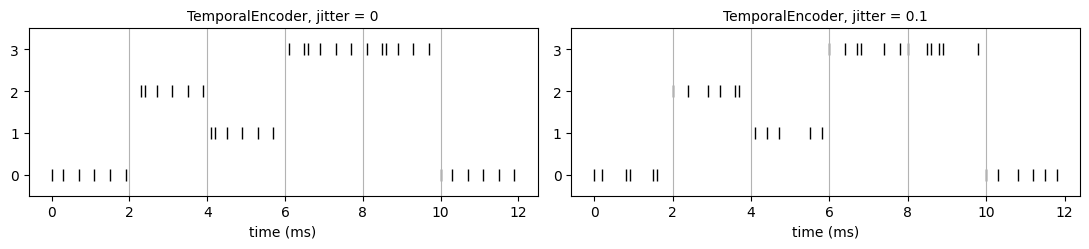

In [10]:
sequence = jnp.array([0, 2, 1, 3, 3, 0])
clean = braintools.TemporalEncoder(n_patterns=4, pattern_length=20, jitter=0.0)(sequence)
noisy = braintools.TemporalEncoder(n_patterns=4, pattern_length=20, jitter=0.1)(sequence)
print("output shape:", clean.shape)
decoded = np.asarray(clean.reshape(len(sequence), 20, 4).sum(axis=1).argmax(axis=1))
print("decoded from the active neuron in each slot:", decoded, "(sequence", np.asarray(sequence), ")")

fig, axes = plt.subplots(1, 2, figsize=(11, 2.6))
raster(axes[0], clean, "TemporalEncoder, jitter = 0")
raster(axes[1], noisy, "TemporalEncoder, jitter = 0.1")
for ax in axes:
    for k in range(1, len(sequence)):
        ax.axvline(k * 20 * dt.to_decimal(u.ms), color="0.7", lw=0.8)
fig.tight_layout()
plt.show()

## Choosing an Encoder

| Data and goal | Encoder |
|---|---|
| Intensities, rate-coded networks, firing rates in Hz | `RateEncoder`, `PoissonEncoder` |
| A fixed spike probability per step (e.g. pixels shown for N steps) | `BernoulliEncoder` |
| A scalar represented by many neurons, robust to noise | `PopulationEncoder` |
| One spike per feature, fast, deterministic | `LatencyEncoder` (`'linear'` for evenly spread inputs), `RankOrderEncoder` |
| An exact, reproducible number of spikes | `SpikeCountEncoder` |
| A continuous time series, event-based | `DeltaEncoder` |
| Driving a neuron model with current | `StepCurrentEncoder` |
| Discrete symbol sequences | `TemporalEncoder` |

## Summary

- `n_time` is a number of steps for every encoder; rates in Hz use the `brainstate` time step, whatever its unit.
- Rate encoders fire with probability $\text{rate}\cdot dt$ (`PoissonEncoder`: $1 - e^{-\text{rate}\cdot dt}$); `BernoulliEncoder` sets the probability per step directly.
- `LatencyEncoder` with `normalize=True` spans the window; the log code compresses inputs well above threshold toward the start.
- `DeltaEncoder` is send-on-delta: signed events whose cumulative sum tracks the signal to about one threshold.